# Comparación de resultados y selección del modelo ganador

**Proyecto:** conteo de gallinas

**Objetivo:** consolidar y comparar, en el orden en que se ejecutaron, los resultados de las cuatro etapas de experimentación con YOLO y **quedarse con el modelo ganador**.

| # | Etapa | Archivo | Qué compara |
|---|-------|---------|-------------|
| 1 | Modelos baseline | `artifacts/modelos_baselines_11.csv` | `yolo26m`, `yolo12m`, `yolo11m`, `yolov10m` |
| 2 | Grid Search | `artifacts/yolo26_ft_gs_11.csv` | épocas, batch, learning rate y optimizador (72 corridas) |
| 3 | Optuna | `artifacts/yolo26_ft_opt_11.csv` | espacio continuo de hiperparámetros (72 trials) |
| 4 | Data Augmentation | `artifacts/yolo26_data_augmentation_11.csv` | 9 parámetros de aumento sobre la config. ganadora de Optuna (15 trials) |


## 0. Configuración y carga de datos

In [1]:
import os
os.chdir(r"B:\12RossyDocumentos\12ProyectoGallinas\11Avance\13_proyecto_gallinas")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
)

DIR_ARTIFACTS = Path("artifacts")

PALETA = {
    "yolo26m": "#4C72B0",
    "yolo12m": "#DD8452",
    "yolo11m": "#55A868",
    "yolov10m": "#C44E52",
    "SGD": "#4C72B0",
    "auto": "#DD8452",
}


def minmax(serie, invertir=False):
    '''Escala una serie al rango [0, 1] (min-max).'''
    minimo, maximo = serie.min(), serie.max()
    if maximo == minimo:
        return pd.Series(1.0, index=serie.index)
    escalada = (serie - minimo) / (maximo - minimo)
    return 1 - escalada if invertir else escalada


def score_compuesto(df, pesos):
    '''Suma ponderada de métricas normalizadas (0-1).'''
    score = pd.Series(0.0, index=df.index)
    for columna, peso in pesos.items():
        score = score + peso * minmax(df[columna])
    return score.round(4)


def barras_horizontales(serie, titulo, xlabel, color="#4C72B0",
                        color_negativo="#C44E52", fmt="{:.4f}", figsize=(9, 4)):
    '''Barras horizontales que admiten valores negativos (correlaciones).'''
    orden = serie.sort_values()
    rango = orden.max() - orden.min()
    margen = rango * 0.18 if rango != 0 else abs(orden.max()) * 0.2 + 0.1

    fig, ax = plt.subplots(figsize=figsize)
    colores = [color if valor >= 0 else color_negativo for valor in orden.values]
    ax.barh([str(indice) for indice in orden.index], orden.values, color=colores)

    for y, valor in enumerate(orden.values):
        desplazamiento = margen * 0.12 * (1 if valor >= 0 else -1)
        ax.text(valor + desplazamiento, y, fmt.format(valor), va="center",
                ha="left" if valor >= 0 else "right", fontsize=9)

    if orden.min() < 0:
        ax.axvline(0, color="black", linewidth=0.8)

    ax.set_xlim(orden.min() - margen, orden.max() + margen)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

In [2]:
archivos = {
    "baseline": DIR_ARTIFACTS / "modelos_baselines_11.csv",
    "grid_search": DIR_ARTIFACTS / "yolo26_ft_gs_11.csv",
    "optuna": DIR_ARTIFACTS / "yolo26_ft_opt_11.csv",
    "data_augmentation": DIR_ARTIFACTS / "yolo26_data_augmentation_11.csv",
}

faltantes = [str(ruta) for ruta in archivos.values() if not ruta.exists()]
assert not faltantes, f"Faltan archivos de resultados: {faltantes}"

df_baseline = pd.read_csv(archivos["baseline"])
df_gs = pd.read_csv(archivos["grid_search"])
df_opt = pd.read_csv(archivos["optuna"])
df_aug = pd.read_csv(archivos["data_augmentation"])

# Optuna y Data Augmentation guardan la métrica objetivo en la columna "value"
df_opt = df_opt.rename(columns={"value": "map50_95"})
df_aug = df_aug.rename(columns={"value": "map50_95"})

for df in (df_opt, df_aug):
    df["tiempo_minutos"] = pd.to_timedelta(df["duration"]).dt.total_seconds() / 60
    df["tiempo_horas"] = df["tiempo_minutos"] / 60

# Productividad: mAP50-95 obtenido por minuto de entrenamiento
df_baseline["map50_95_por_min"] = df_baseline["map50_95"] / df_baseline["tiempo_minutos"]
df_gs["map50_95_por_min"] = df_gs["map50_95"] / df_gs["tiempo_minutos"]
df_opt["map50_95_por_min"] = df_opt["map50_95"] / df_opt["tiempo_minutos"]
df_aug["map50_95_por_min"] = df_aug["map50_95"] / df_aug["tiempo_minutos"]

print("Dimensiones de cada archivo:")
for nombre, df in [("baseline", df_baseline), ("grid_search", df_gs),
                   ("optuna", df_opt), ("data_augmentation", df_aug)]:
    print(f"  {nombre:<18} {df.shape[0]:>3} filas x {df.shape[1]:>2} columnas")

Dimensiones de cada archivo:
  baseline             4 filas x 16 columnas
  grid_search         72 filas x 17 columnas
  optuna              72 filas x 13 columnas
  data_augmentation   15 filas x 18 columnas


In [3]:
resumen_entrada = pd.DataFrame([
    {
        "etapa": "1. Baseline",
        "archivo": archivos["baseline"].name,
        "experimentos": len(df_baseline),
        "metricas_completas": "Sí",
        "mejor_map50_95": df_baseline["map50_95"].max(),
        "nulos": int(df_baseline.isna().sum().sum()),
        "tiempo_total_min": df_baseline["tiempo_minutos"].sum(),
    },
    {
        "etapa": "2. Grid Search",
        "archivo": archivos["grid_search"].name,
        "experimentos": len(df_gs),
        "metricas_completas": "Sí",
        "mejor_map50_95": df_gs["map50_95"].max(),
        "nulos": int(df_gs.isna().sum().sum()),
        "tiempo_total_min": df_gs["tiempo_minutos"].sum(),
    },
    {
        "etapa": "3. Optuna",
        "archivo": archivos["optuna"].name,
        "experimentos": len(df_opt),
        "metricas_completas": "No (solo objetivo)",
        "mejor_map50_95": df_opt["map50_95"].max(),
        "nulos": int(df_opt.isna().sum().sum()),
        "tiempo_total_min": df_opt["tiempo_minutos"].sum(),
    },
    {
        "etapa": "4. Data Augmentation",
        "archivo": archivos["data_augmentation"].name,
        "experimentos": len(df_aug),
        "metricas_completas": "No (solo objetivo)",
        "mejor_map50_95": df_aug["map50_95"].max(),
        "nulos": int(df_aug.isna().sum().sum()),
        "tiempo_total_min": df_aug["tiempo_minutos"].sum(),
    },
])
resumen_entrada["tiempo_total_h"] = resumen_entrada["tiempo_total_min"] / 60

print("Estados Optuna:", df_opt["state"].value_counts().to_dict())
print("Estados Data Augmentation:", df_aug["state"].value_counts().to_dict())
print("Trials completos:", int((df_opt["state"] == "COMPLETE").sum()), "y",
      int((df_aug["state"] == "COMPLETE").sum()))
print("Valores nulos totales:", int(resumen_entrada["nulos"].sum()))

resumen_entrada

Estados Optuna: {'COMPLETE': 72}
Estados Data Augmentation: {'COMPLETE': 15}
Trials completos: 72 y 15
Valores nulos totales: 0


,etapa,archivo,experimentos,metricas_completas,mejor_map50_95,nulos,tiempo_total_min,tiempo_total_h
0,1. Baseline,modelos_baselines_11.csv,4,Sí,0.2495,0,19.0748,0.3179
1,2. Grid Search,yolo26_ft_gs_11.csv,72,Sí,0.2617,0,390.5227,6.5087
2,3. Optuna,yolo26_ft_opt_11.csv,72,No (solo objetivo),0.2596,0,668.7913,11.1465
3,4. Data Augmentation,yolo26_data_augmentation_11.csv,15,No (solo objetivo),0.2545,0,213.9829,3.5664


**Lectura de la tabla anterior.** Los cuatro archivos están completos (sin nulos y con todos los trials en estado `COMPLETE`). Solo el baseline y el Grid Search guardaron mAP50, precisión y recall; Optuna y Data Augmentation registraron únicamente la métrica optimizada. El costo total de experimentación ronda las **21.5 horas** de GPU, concentradas en Optuna (≈11 h) y Grid Search (≈6.5 h).

---

## 1. Comparación de modelos baseline (YOLO)

In [4]:
columnas_baseline = [
    "modelo_yolo", "epocas_fin", "batch", "learning_rate", "optimizer",
    "tiempo_minutos", "map50", "map50_95", "precision", "recall",
    "map50_95_por_min",
]

tabla_baseline = (
    df_baseline[columnas_baseline]
    .sort_values("map50_95", ascending=False)
    .reset_index(drop=True)
)
tabla_baseline.insert(0, "ranking", tabla_baseline.index + 1)

fila_baseline = tabla_baseline.iloc[0]
fila_yolo26m = df_baseline.loc[df_baseline["modelo_yolo"] == "yolo26m"].iloc[0]

print("Ranking por mAP50-95:")
print(tabla_baseline[["ranking", "modelo_yolo", "map50", "map50_95", "precision", "recall"]]
      .to_string(index=False))
print()
print(f"Ganador baseline: {fila_baseline['modelo_yolo']} (mAP50-95 = {fila_baseline['map50_95']:.5f})")
print(f"Diferencia yolo26m vs. ganador: {fila_yolo26m['map50_95'] - fila_baseline['map50_95']:+.5f} "
      f"({100 * (fila_yolo26m['map50_95'] / fila_baseline['map50_95'] - 1):+.2f}% relativo)")

tabla_baseline

Ranking por mAP50-95:
 ranking modelo_yolo  map50  map50_95  precision  recall
       1     yolo12m 0.6542    0.2495     0.6571  0.6657
       2     yolo26m 0.6583    0.2454     0.6854  0.6430
       3     yolo11m 0.6376    0.2393     0.6639  0.6433
       4    yolov10m 0.6339    0.2335     0.6367  0.6544

Ganador baseline: yolo12m (mAP50-95 = 0.24946)
Diferencia yolo26m vs. ganador: -0.00402 (-1.61% relativo)


,ranking,modelo_yolo,epocas_fin,batch,learning_rate,optimizer,tiempo_minutos,map50,map50_95,precision,recall,map50_95_por_min
0,1,yolo12m,100,16,0.0100,auto,4.9169,0.6542,0.2495,0.6571,0.6657,0.0507
1,2,yolo26m,100,16,0.0100,auto,4.8573,0.6583,0.2454,0.6854,0.6430,0.0505
2,3,yolo11m,100,16,0.0100,auto,4.5199,0.6376,0.2393,0.6639,0.6433,0.0529
3,4,yolov10m,100,16,0.0100,auto,4.7808,0.6339,0.2335,0.6367,0.6544,0.0488


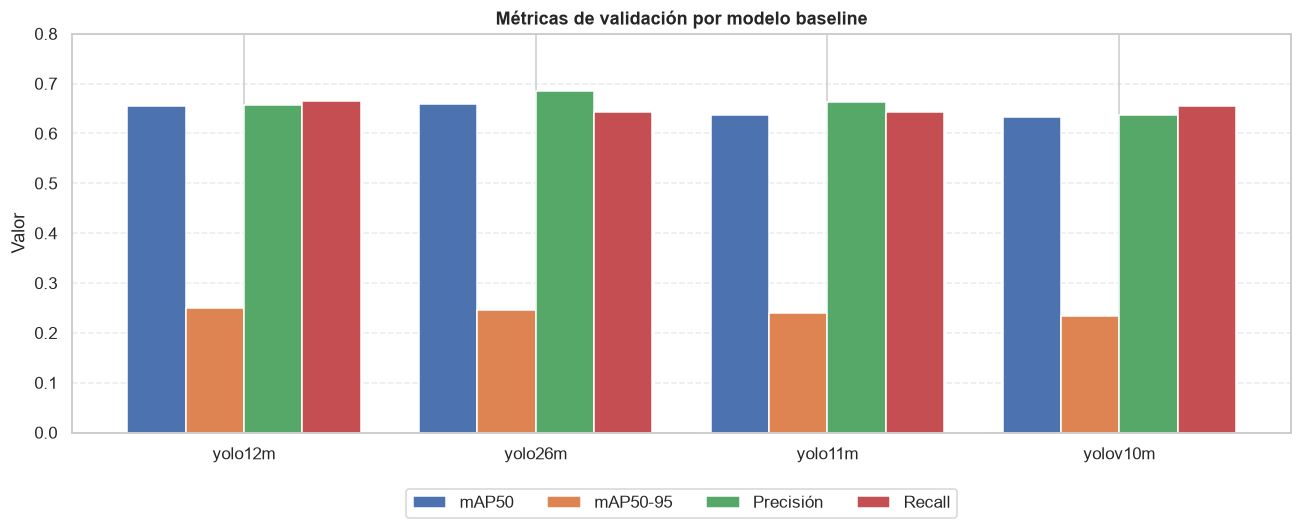

In [5]:
metricas_plot = {
    "map50": "mAP50",
    "map50_95": "mAP50-95",
    "precision": "Precisión",
    "recall": "Recall",
}

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(tabla_baseline))
ancho = 0.2

for i, (columna, etiqueta) in enumerate(metricas_plot.items()):
    ax.bar(x + (i - 1.5) * ancho, tabla_baseline[columna], ancho, label=etiqueta)

ax.set_xticks(x)
ax.set_xticklabels(tabla_baseline["modelo_yolo"])
ax.set_ylim(0, 0.8)
ax.set_ylabel("Valor")
ax.set_title("Métricas de validación por modelo baseline")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

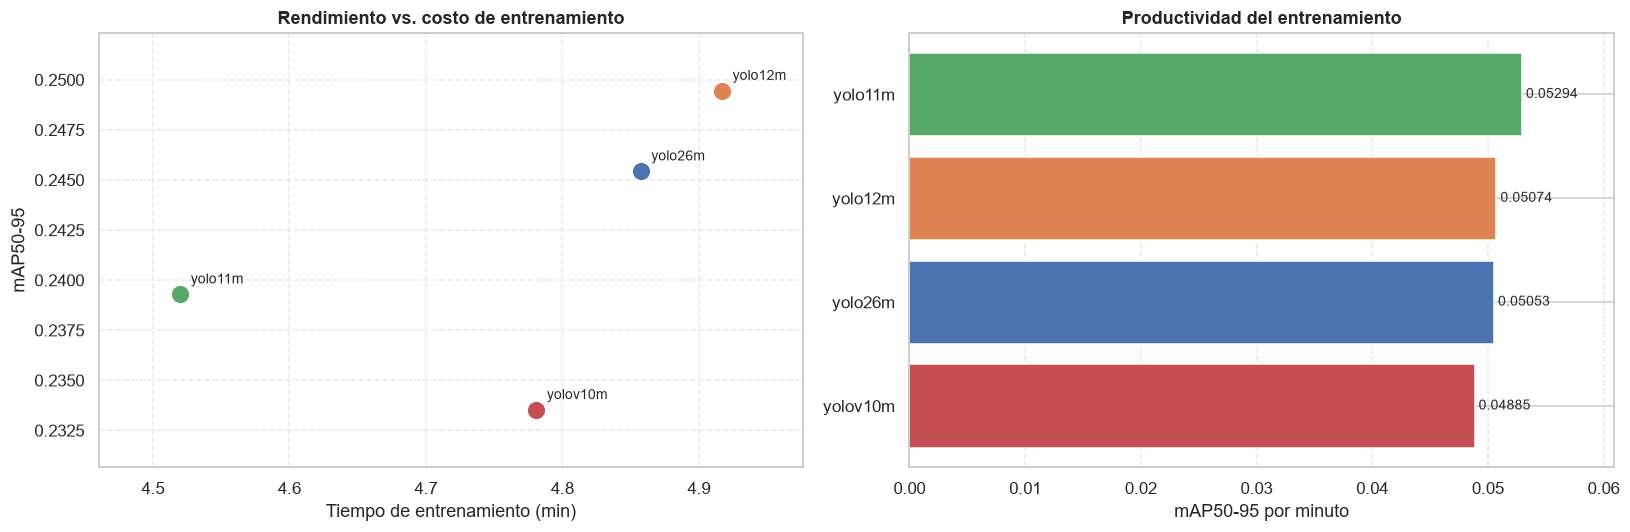

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
for _, fila in tabla_baseline.iterrows():
    ax.scatter(fila["tiempo_minutos"], fila["map50_95"], s=150,
               color=PALETA[fila["modelo_yolo"]], edgecolor="white", zorder=3)
    ax.annotate(fila["modelo_yolo"], (fila["tiempo_minutos"], fila["map50_95"]),
                xytext=(7, 7), textcoords="offset points", fontsize=9)
ax.set_xlabel("Tiempo de entrenamiento (min)")
ax.set_ylabel("mAP50-95")
ax.set_title("Rendimiento vs. costo de entrenamiento")
ax.margins(x=0.15, y=0.18)
ax.grid(True, linestyle="--", alpha=0.4)

ax = axes[1]
productividad = tabla_baseline.set_index("modelo_yolo")["map50_95_por_min"].sort_values()
colores = [PALETA[modelo] for modelo in productividad.index]
ax.barh(productividad.index, productividad.values, color=colores)
for y, valor in enumerate(productividad.values):
    ax.text(valor, y, f" {valor:.5f}", va="center", fontsize=9)
ax.set_xlim(0, productividad.max() * 1.15)
ax.set_xlabel("mAP50-95 por minuto")
ax.set_title("Productividad del entrenamiento")
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()



## 2. Grid Search sobre yolo26m

In [11]:
columnas_gs = [
    "numero", "epocas_inicial", "epocas_fin", "batch", "learning_rate", "optimizer",
    "tiempo_minutos", "map50", "map50_95", "precision", "recall", "map50_95_por_min",
]

tabla_gs = (
    df_gs[columnas_gs]
    .sort_values("map50_95", ascending=False)
    .reset_index(drop=True)
)
tabla_gs.insert(0, "ranking", tabla_gs.index + 1)

print(f"Corridas: {len(df_gs)} | "
      f"combinaciones nominales: {df_gs['epocas_inicial'].nunique()} épocas × "
      f"{df_gs['batch'].nunique()} batch × {df_gs['learning_rate'].nunique()} lr × "
      f"{df_gs['optimizer'].nunique()} optimizadores = "
      f"{df_gs['epocas_inicial'].nunique() * df_gs['batch'].nunique() * df_gs['learning_rate'].nunique() * df_gs['optimizer'].nunique()}")
print(f"Mejor mAP50-95: {df_gs['map50_95'].max():.5f} | "
      f"peor: {df_gs['map50_95'].min():.5f}")
print(f"Tiempo total: {df_gs['tiempo_minutos'].sum() / 60:.2f} h")

tabla_gs.head(10)

Corridas: 72 | combinaciones nominales: 3 épocas × 4 batch × 3 lr × 2 optimizadores = 72
Mejor mAP50-95: 0.26174 | peor: 0.09199
Tiempo total: 6.51 h


,ranking,numero,epocas_inicial,epocas_fin,batch,learning_rate,optimizer,tiempo_minutos,map50,map50_95,precision,recall,map50_95_por_min
0,1,27,100,100,6,0.0100,SGD,5.7630,0.6686,0.2617,0.6740,0.6550,0.0454
1,2,33,100,100,8,0.0100,SGD,5.3300,0.6711,0.2599,0.6649,0.6790,0.0488
2,3,39,100,100,10,0.0100,SGD,4.8037,0.6612,0.2588,0.6890,0.6345,0.0539
3,4,45,100,100,12,0.0100,SGD,4.7815,0.6747,0.2563,0.6861,0.6642,0.0536
4,5,57,150,150,8,0.0100,SGD,7.7451,0.6704,0.2560,0.6777,0.6655,0.0331
5,6,51,150,150,6,0.0100,SGD,8.4620,0.6705,0.2551,0.6742,0.6533,0.0301
6,7,63,150,150,10,0.0100,SGD,7.0843,0.6685,0.2550,0.6660,0.6648,0.0360
7,8,69,150,150,12,0.0100,SGD,6.9945,0.6654,0.2530,0.6707,0.6539,0.0362
8,9,18,50,50,10,0.0010,auto,2.6433,0.6618,0.2527,0.6677,0.6575,0.0956
9,10,14,50,50,10,0.1000,auto,2.7008,0.6618,0.2527,0.6677,0.6575,0.0936


In [41]:
metricas_gs = ["map50", "map50_95", "precision", "recall"]
df_gs["firma_metricas"] = (
    df_gs[metricas_gs].round(6).astype(str).agg("|".join, axis=1)
)

duplicados = df_gs[df_gs.duplicated("firma_metricas", keep=False)]
resumen_duplicados = (
    duplicados
    .groupby(["epocas_inicial", "batch", "optimizer"])
    .agg(filas=("numero", "size"),
         lr_distintos=("learning_rate", "nunique"),
         map50_95=("map50_95", "first"))
    .reset_index()
)

print(f"Filas implicadas en grupos con métricas idénticas: {len(duplicados)} "
      f"(se eliminan {len(duplicados) - duplicados['firma_metricas'].nunique()})")
print(f"Todas usan optimizer='auto': {(duplicados['optimizer'] == 'auto').all()}")
print(f"Experimentos únicos según métricas: {df_gs['firma_metricas'].nunique()} de {len(df_gs)}")
print("Causa: con optimizer='auto' Ultralytics ignora lr0, "
      "por lo que 3 valores de lr producen la misma corrida.")

resumen_duplicados

Filas implicadas en grupos con métricas idénticas: 36 (se eliminan 24)
Todas usan optimizer='auto': True
Experimentos únicos según métricas: 48 de 72
Causa: con optimizer='auto' Ultralytics ignora lr0, por lo que 3 valores de lr producen la misma corrida.


,epocas_inicial,batch,optimizer,filas,lr_distintos,map50_95
0,50,6,auto,3,3,0.2420
1,50,8,auto,3,3,0.2496
2,50,10,auto,3,3,0.2527
3,50,12,auto,3,3,0.2499
4,100,6,auto,3,3,0.2481
5,100,8,auto,3,3,0.2472
6,100,10,auto,3,3,0.2515
7,100,12,auto,3,3,0.2449
8,150,6,auto,3,3,0.2459
9,150,8,auto,3,3,0.2429


Experimentos únicos tras deduplicar: 48
Mejor tras deduplicar: 0.26174 (no cambia el ganador)


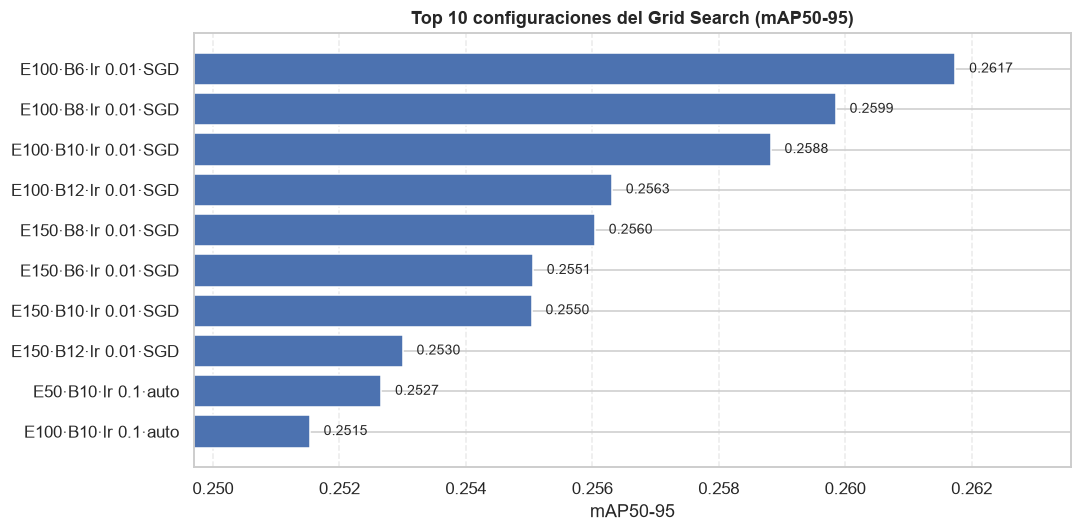

,ranking,numero,config,tiempo_minutos,map50,map50_95,precision,recall
0,1,27,E100·B6·lr 0.01·SGD,5.7630,0.6686,0.2617,0.6740,0.6550
1,2,33,E100·B8·lr 0.01·SGD,5.3300,0.6711,0.2599,0.6649,0.6790
2,3,39,E100·B10·lr 0.01·SGD,4.8037,0.6612,0.2588,0.6890,0.6345
3,4,45,E100·B12·lr 0.01·SGD,4.7815,0.6747,0.2563,0.6861,0.6642
4,5,57,E150·B8·lr 0.01·SGD,7.7451,0.6704,0.2560,0.6777,0.6655
5,6,51,E150·B6·lr 0.01·SGD,8.4620,0.6705,0.2551,0.6742,0.6533
6,7,63,E150·B10·lr 0.01·SGD,7.0843,0.6685,0.2550,0.6660,0.6648
7,8,69,E150·B12·lr 0.01·SGD,6.9945,0.6654,0.2530,0.6707,0.6539
8,9,14,E50·B10·lr 0.1·auto,2.7008,0.6618,0.2527,0.6677,0.6575
9,10,38,E100·B10·lr 0.1·auto,5.1652,0.6700,0.2515,0.6810,0.6435


In [42]:
# Se conserva una fila por experimento real (métricas idénticas = misma corrida)
df_gs_u = df_gs.drop_duplicates("firma_metricas").copy()
df_gs_u["config"] = df_gs_u.apply(
    lambda fila: f"E{int(fila['epocas_inicial'])}·B{int(fila['batch'])}"
                 f"·lr {fila['learning_rate']:g}·{fila['optimizer']}",
    axis=1,
)

tabla_gs_u = (
    df_gs_u
    .sort_values("map50_95", ascending=False)
    .reset_index(drop=True)
)
tabla_gs_u.insert(0, "ranking", tabla_gs_u.index + 1)

print(f"Experimentos únicos tras deduplicar: {len(df_gs_u)}")
print(f"Mejor tras deduplicar: {df_gs_u['map50_95'].max():.5f} "
      f"(no cambia el ganador)")

top10_gs = tabla_gs_u.head(10)

barras_horizontales(
    top10_gs.set_index("config")["map50_95"],
    "Top 10 configuraciones del Grid Search (mAP50-95)",
    "mAP50-95",
    color="#4C72B0",
    figsize=(10, 5),
)

top10_gs[["ranking", "numero", "config", "tiempo_minutos", "map50", "map50_95",
          "precision", "recall"]]

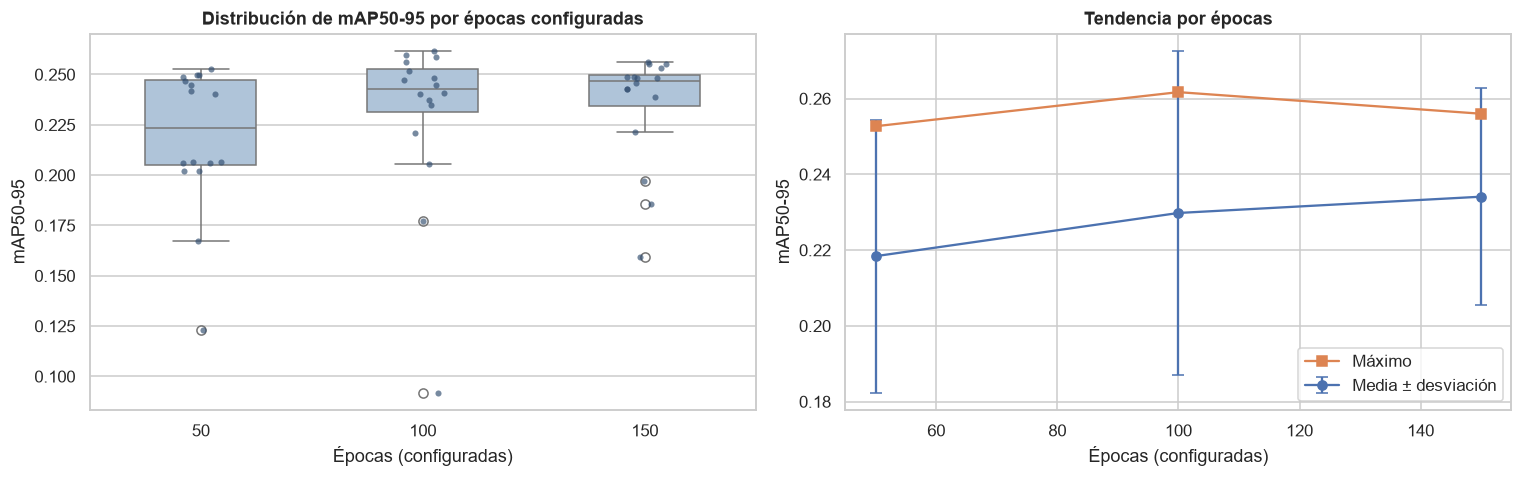

,experimentos,media,mediana,maximo,desviacion
epocas_inicial,,,,,
50,16,0.2184,0.2234,0.2527,0.0360
100,16,0.2298,0.2428,0.2617,0.0428
150,16,0.2341,0.2470,0.2560,0.0287


In [43]:
resumen_epocas = (
    df_gs_u
    .groupby("epocas_inicial")["map50_95"]
    .agg(experimentos="count", media="mean", mediana="median",
         maximo="max", desviacion="std")
    .round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.boxplot(data=df_gs_u, x="epocas_inicial", y="map50_95",
            color="#A8C4E0", width=0.5, ax=axes[0])
sns.stripplot(data=df_gs_u, x="epocas_inicial", y="map50_95",
              color="#2F4B6E", size=4, alpha=0.65, ax=axes[0])
axes[0].set_title("Distribución de mAP50-95 por épocas configuradas")
axes[0].set_xlabel("Épocas (configuradas)")
axes[0].set_ylabel("mAP50-95")

axes[1].errorbar(resumen_epocas.index, resumen_epocas["media"],
                 yerr=resumen_epocas["desviacion"], marker="o", capsize=4,
                 color="#4C72B0", label="Media ± desviación")
axes[1].plot(resumen_epocas.index, resumen_epocas["maximo"], marker="s",
             color="#DD8452", label="Máximo")
axes[1].set_title("Tendencia por épocas")
axes[1].set_xlabel("Épocas (configuradas)")
axes[1].set_ylabel("mAP50-95")
axes[1].legend()

plt.tight_layout()
plt.show()

resumen_epocas

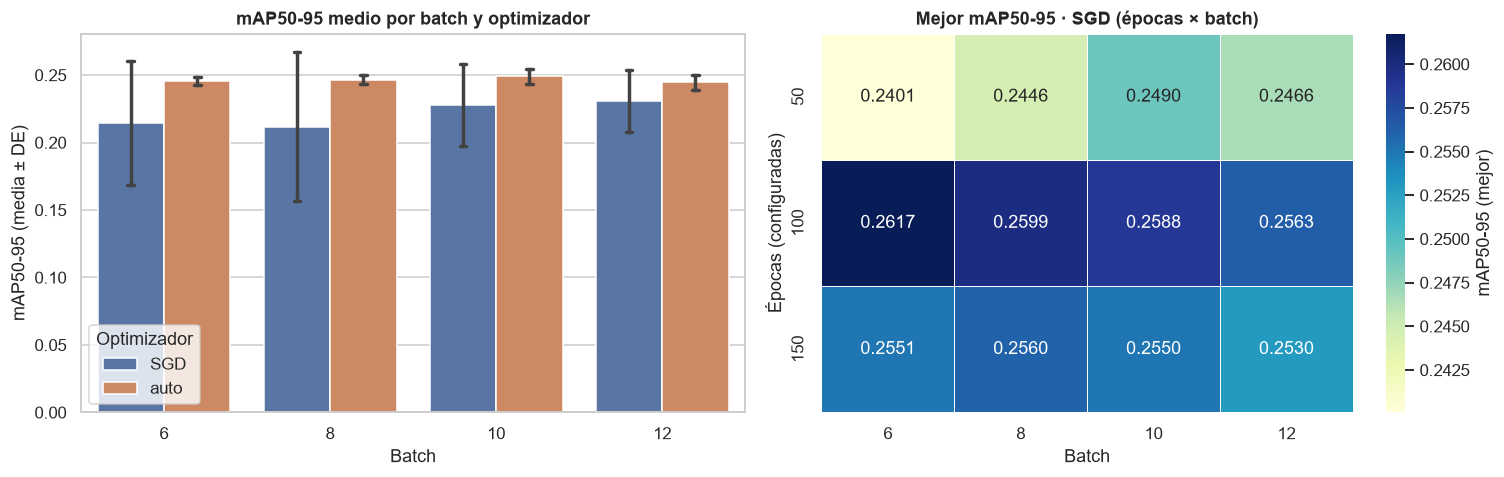

experimentos  media  maximo  desviacion
batch optimizer                                         
6     SGD                   9 0.2142  0.2617      0.0459
      auto                  3 0.2453  0.2481      0.0031
8     SGD                   9 0.2118  0.2599      0.0554
      auto                  3 0.2465  0.2496      0.0034
10    SGD                   9 0.2280  0.2588      0.0305
      auto                  3 0.2490  0.2527      0.0054
12    SGD                   9 0.2305  0.2563      0.0230
      auto                  3 0.2446  0.2499      0.0055

In [44]:
resumen_batch = (
    df_gs_u
    .groupby(["batch", "optimizer"])["map50_95"]
    .agg(experimentos="count", media="mean", maximo="max", desviacion="std")
    .round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(data=df_gs_u, x="batch", y="map50_95", hue="optimizer",
            palette=PALETA, errorbar="sd", capsize=0.08, ax=axes[0])
axes[0].set_title("mAP50-95 medio por batch y optimizador")
axes[0].set_xlabel("Batch")
axes[0].set_ylabel("mAP50-95 (media ± DE)")
axes[0].legend(title="Optimizador")

pivote_sgd = (
    df_gs_u[df_gs_u["optimizer"] == "SGD"]
    .pivot_table(index="epocas_inicial", columns="batch",
                 values="map50_95", aggfunc="max")
)
sns.heatmap(pivote_sgd, annot=True, fmt=".4f", cmap="YlGnBu", ax=axes[1],
            cbar_kws={"label": "mAP50-95 (mejor)"}, linewidths=0.5)
axes[1].set_title("Mejor mAP50-95 · SGD (épocas × batch)")
axes[1].set_xlabel("Batch")
axes[1].set_ylabel("Épocas (configuradas)")

plt.tight_layout()
plt.show()

resumen_batch

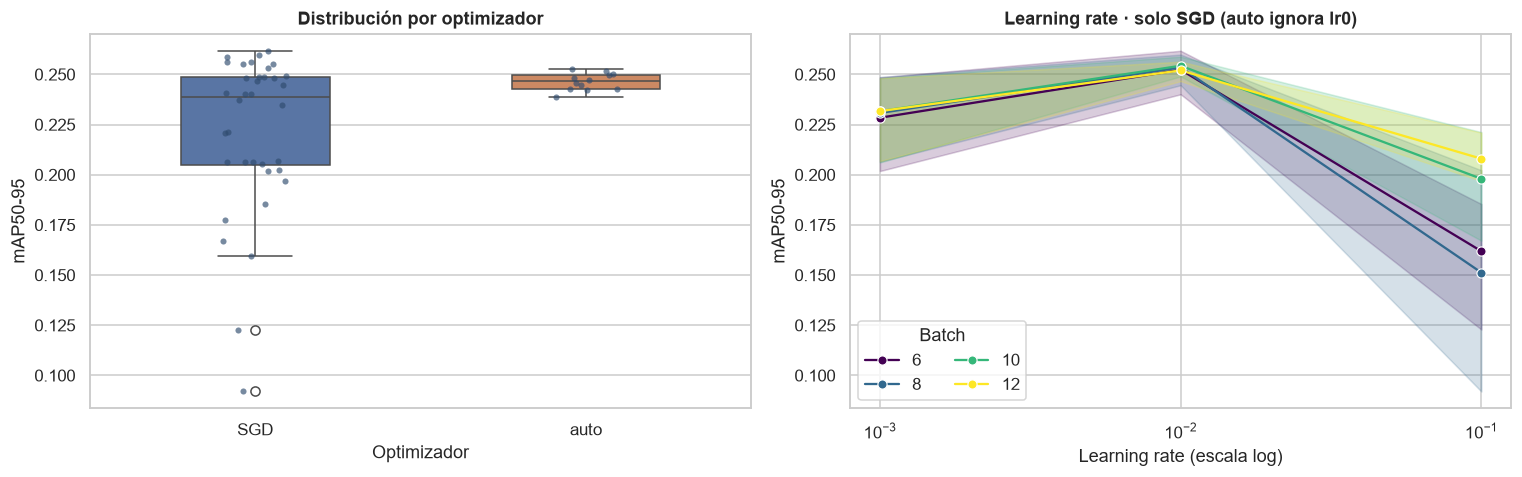

Resumen por optimizador:
           experimentos  media  mediana  maximo  desviacion
optimizer                                                  
SGD                  36 0.2211   0.2386  0.2617      0.0398
auto                 12 0.2464   0.2465  0.2527      0.0042

Resumen por learning rate (SGD):
               experimentos  media  maximo
learning_rate                             
0.0010                   12 0.2306  0.2487
0.0100                   12 0.2530  0.2617
0.1000                   12 0.1798  0.2212


In [45]:
resumen_optimizer = (
    df_gs_u
    .groupby("optimizer")["map50_95"]
    .agg(experimentos="count", media="mean", mediana="median",
         maximo="max", desviacion="std")
    .round(4)
)

resumen_lr = (
    df_gs_u[df_gs_u["optimizer"] == "SGD"]
    .groupby("learning_rate")["map50_95"]
    .agg(experimentos="count", media="mean", maximo="max")
    .round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.boxplot(data=df_gs_u, x="optimizer", y="map50_95", hue="optimizer",
            palette=PALETA, width=0.45, legend=False, ax=axes[0])
sns.stripplot(data=df_gs_u, x="optimizer", y="map50_95",
              color="#2F4B6E", size=4, alpha=0.65, ax=axes[0])
axes[0].set_title("Distribución por optimizador")
axes[0].set_xlabel("Optimizador")
axes[0].set_ylabel("mAP50-95")

sns.lineplot(data=df_gs_u[df_gs_u["optimizer"] == "SGD"],
             x="learning_rate", y="map50_95", hue="batch",
             marker="o", palette="viridis", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Learning rate · solo SGD (auto ignora lr0)")
axes[1].set_xlabel("Learning rate (escala log)")
axes[1].set_ylabel("mAP50-95")
axes[1].legend(title="Batch", ncol=2)

plt.tight_layout()
plt.show()

print("Resumen por optimizador:")
print(resumen_optimizer.to_string())
print()
print("Resumen por learning rate (SGD):")
print(resumen_lr.to_string())

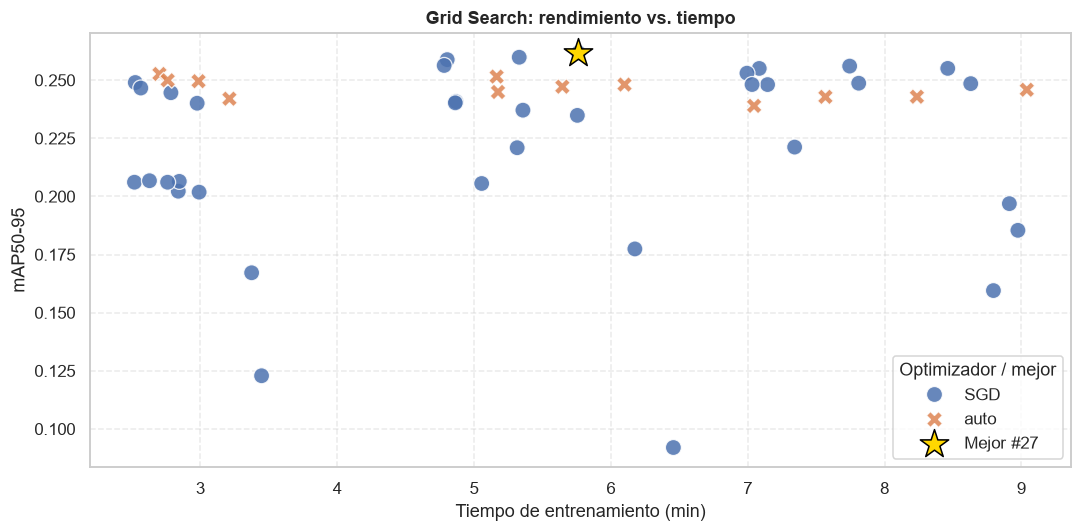

,numero,config,tiempo_minutos,map50_95,map50_95_por_min
14,15,E50·B10·lr 0.01·SGD,2.5240,0.2490,0.0987
20,21,E50·B12·lr 0.01·SGD,2.5645,0.2466,0.0962
13,14,E50·B10·lr 0.1·auto,2.7008,0.2527,0.0936
19,20,E50·B12·lr 0.1·auto,2.7611,0.2499,0.0905
8,9,E50·B8·lr 0.01·SGD,2.7846,0.2446,0.0878


In [46]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.scatterplot(data=df_gs_u, x="tiempo_minutos", y="map50_95",
                hue="optimizer", style="optimizer", s=110,
                palette=PALETA, ax=ax, alpha=0.85)

mejor_gs = df_gs.loc[df_gs["map50_95"].idxmax()]
ax.scatter(mejor_gs["tiempo_minutos"], mejor_gs["map50_95"], marker="*",
           s=380, color="gold", edgecolor="black", zorder=5,
           label=f"Mejor #{int(mejor_gs['numero'])}")

ax.set_xlabel("Tiempo de entrenamiento (min)")
ax.set_ylabel("mAP50-95")
ax.set_title("Grid Search: rendimiento vs. tiempo")
ax.legend(title="Optimizador / mejor")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

tabla_productividad_gs = df_gs_u.nlargest(5, "map50_95_por_min")[
    ["numero", "config", "tiempo_minutos", "map50_95", "map50_95_por_min"]
]
tabla_productividad_gs



## 3. Optimización con Optuna

In [48]:
df_opt["optimizer"] = df_opt["params_MODEL_OPTIMIZER"]
df_opt["batch"] = df_opt["params_MODEL_BATCH"]
df_opt["epochs"] = df_opt["params_MODEL_EPOCHS"]
df_opt["lr"] = df_opt["params_MODEL_LR"]

print(f"Trials: {len(df_opt)} | completos: {(df_opt['state'] == 'COMPLETE').sum()} | "
      f"tiempo total: {df_opt['tiempo_horas'].sum():.2f} h")
print(f"Mejor mAP50-95: {df_opt['map50_95'].max():.5f} | "
      f"mediana: {df_opt['map50_95'].median():.5f} | "
      f"media: {df_opt['map50_95'].mean():.5f}")

df_opt[["batch", "epochs", "lr", "map50_95", "tiempo_minutos"]].describe().T.round(4)

Trials: 72 | completos: 72 | tiempo total: 11.15 h
Mejor mAP50-95: 0.25962 | mediana: 0.25116 | media: 0.24773


,count,mean,std,min,25%,50%,75%,max
batch,72.0000,10.2778,1.1655,8.0000,9.0000,11.0000,11.0000,12.0000
epochs,72.0000,256.1944,46.0403,100.0000,245.0000,272.0000,287.2500,300.0000
lr,72.0000,0.0206,0.0232,0.0010,0.0050,0.0120,0.0246,0.0986
map50_95,72.0000,0.2477,0.0089,0.2215,0.2417,0.2512,0.2548,0.2596
tiempo_minutos,72.0000,9.2888,1.4237,6.1521,8.5072,9.0277,9.6035,13.3008


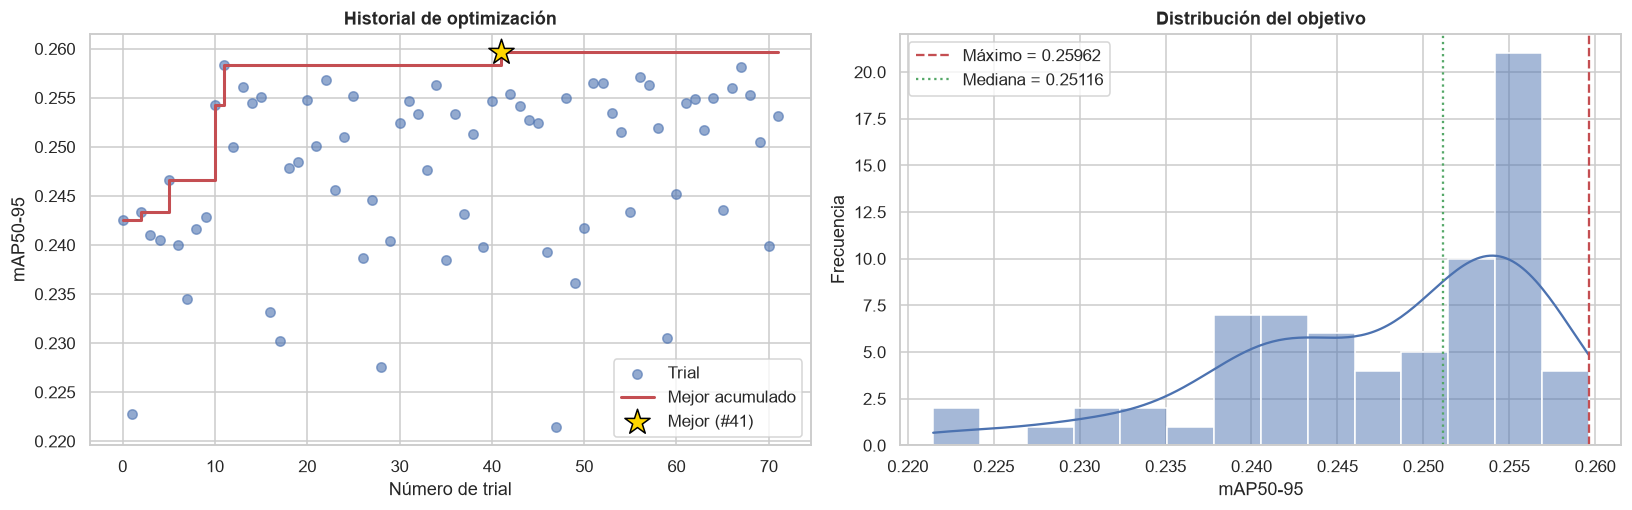

In [49]:
df_hist_opt = df_opt.sort_values("number").copy()
df_hist_opt["mejor_acumulado"] = df_hist_opt["map50_95"].cummax()

mejor_opt = df_opt.loc[df_opt["map50_95"].idxmax()]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

axes[0].scatter(df_hist_opt["number"], df_hist_opt["map50_95"],
                s=38, alpha=0.6, color="#4C72B0", label="Trial")
axes[0].step(df_hist_opt["number"], df_hist_opt["mejor_acumulado"],
             where="post", color="#C44E52", linewidth=2, label="Mejor acumulado")
axes[0].scatter(mejor_opt["number"], mejor_opt["map50_95"], marker="*",
                s=300, color="gold", edgecolor="black", zorder=5,
                label=f"Mejor (#{int(mejor_opt['number'])})")
axes[0].set_xlabel("Número de trial")
axes[0].set_ylabel("mAP50-95")
axes[0].set_title("Historial de optimización")
axes[0].legend()

sns.histplot(df_opt["map50_95"], bins=14, kde=True, color="#4C72B0", ax=axes[1])
axes[1].axvline(mejor_opt["map50_95"], color="#C44E52", linestyle="--",
                label=f"Máximo = {mejor_opt['map50_95']:.5f}")
axes[1].axvline(df_opt["map50_95"].median(), color="#55A868", linestyle=":",
                label=f"Mediana = {df_opt['map50_95'].median():.5f}")
axes[1].set_xlabel("mAP50-95")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title("Distribución del objetivo")
axes[1].legend()

plt.tight_layout()
plt.show()

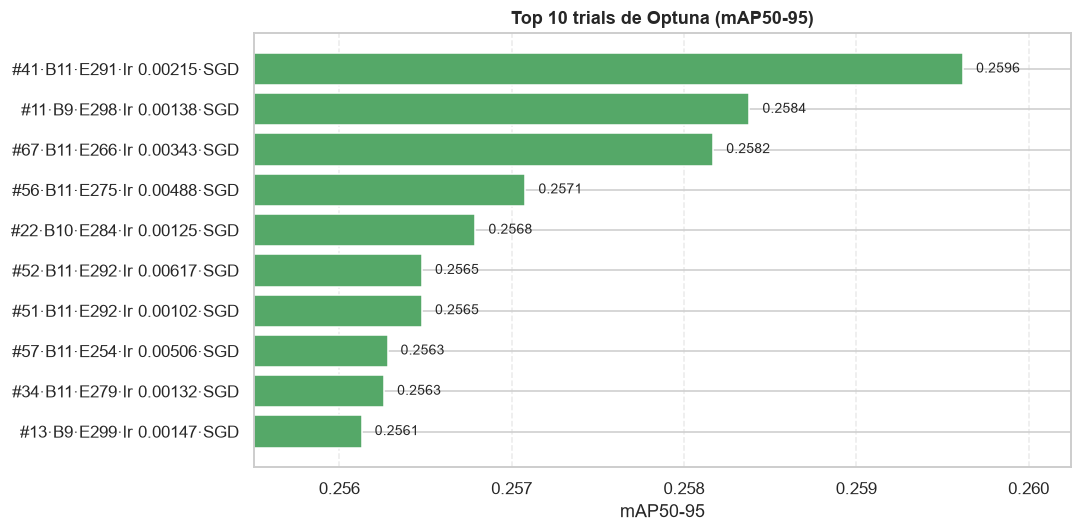

,ranking,number,batch,epochs,lr,optimizer,map50_95,tiempo_minutos,config
0,1,41,11,291,0.0022,SGD,0.2596,9.5808,#41·B11·E291·lr 0.00215·SGD
1,2,11,9,298,0.0014,SGD,0.2584,12.6921,#11·B9·E298·lr 0.00138·SGD
2,3,67,11,266,0.0034,SGD,0.2582,9.1709,#67·B11·E266·lr 0.00343·SGD
3,4,56,11,275,0.0049,SGD,0.2571,8.6866,#56·B11·E275·lr 0.00488·SGD
4,5,22,10,284,0.0013,SGD,0.2568,11.5435,#22·B10·E284·lr 0.00125·SGD
5,6,51,11,292,0.0010,SGD,0.2565,11.7241,#51·B11·E292·lr 0.00102·SGD
6,7,52,11,292,0.0062,SGD,0.2565,8.7251,#52·B11·E292·lr 0.00617·SGD
7,8,57,11,254,0.0051,SGD,0.2563,8.6882,#57·B11·E254·lr 0.00506·SGD
8,9,34,11,279,0.0013,SGD,0.2563,13.3008,#34·B11·E279·lr 0.00132·SGD
9,10,13,9,299,0.0015,SGD,0.2561,12.6661,#13·B9·E299·lr 0.00147·SGD


In [50]:
columnas_opt = ["number", "batch", "epochs", "lr", "optimizer",
                "map50_95", "tiempo_minutos"]

tabla_opt = df_opt[columnas_opt].copy()
tabla_opt["config"] = tabla_opt.apply(
    lambda fila: f"#{int(fila['number'])}·B{int(fila['batch'])}"
                 f"·E{int(fila['epochs'])}·lr {fila['lr']:.5f}·{fila['optimizer']}",
    axis=1,
)
tabla_opt = tabla_opt.sort_values("map50_95", ascending=False).reset_index(drop=True)
tabla_opt.insert(0, "ranking", tabla_opt.index + 1)

top10_opt = tabla_opt.head(10)

barras_horizontales(
    top10_opt.set_index("config")["map50_95"],
    "Top 10 trials de Optuna (mAP50-95)",
    "mAP50-95",
    color="#55A868",
    figsize=(10, 5),
)

top10_opt

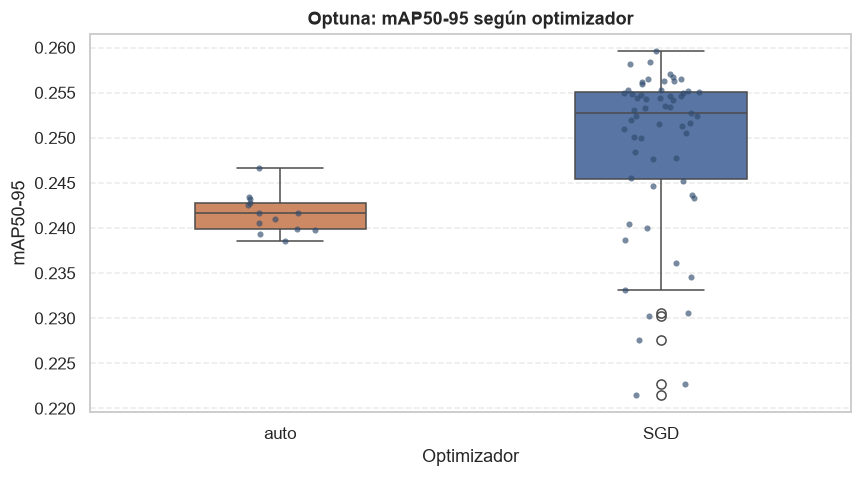

,experimentos,media,mediana,maximo,desviacion
optimizer,,,,,
SGD,59,0.2491,0.2527,0.2596,0.0092
auto,13,0.2416,0.2416,0.2466,0.0022


In [51]:
resumen_opt_optimizer = (
    df_opt
    .groupby("optimizer")["map50_95"]
    .agg(experimentos="count", media="mean", mediana="median",
         maximo="max", desviacion="std")
    .round(4)
)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df_opt, x="optimizer", y="map50_95", hue="optimizer",
            palette=PALETA, width=0.45, legend=False, ax=ax)
sns.stripplot(data=df_opt, x="optimizer", y="map50_95",
              color="#2F4B6E", size=4, alpha=0.65, ax=ax)
ax.set_title("Optuna: mAP50-95 según optimizador")
ax.set_xlabel("Optimizador")
ax.set_ylabel("mAP50-95")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

resumen_opt_optimizer

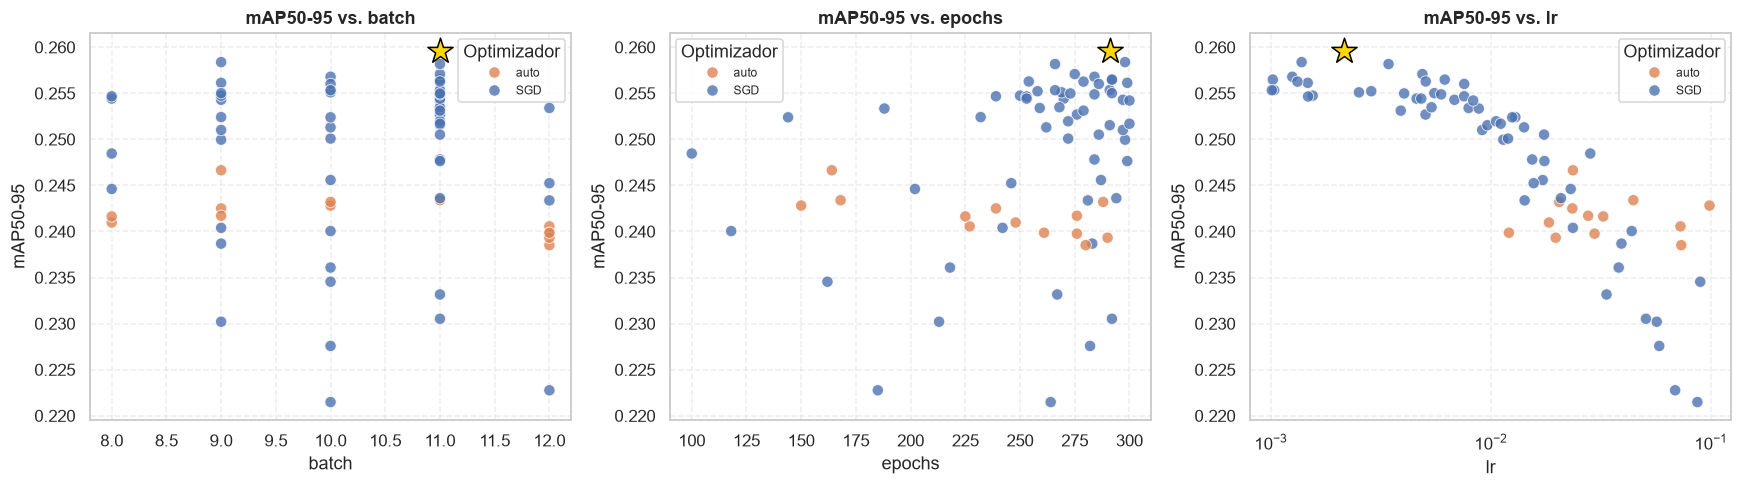

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

for ax, columna, escala in zip(
    axes, ["batch", "epochs", "lr"], ["linear", "linear", "log"]
):
    sns.scatterplot(data=df_opt, x=columna, y="map50_95",
                    hue="optimizer", palette=PALETA, s=55, alpha=0.8, ax=ax)
    ax.scatter(mejor_opt[columna], mejor_opt["map50_95"], marker="*",
               s=300, color="gold", edgecolor="black", zorder=5)
    ax.set_xscale(escala)
    ax.set_title(f"mAP50-95 vs. {columna}")
    ax.set_xlabel(columna)
    ax.set_ylabel("mAP50-95")
    ax.legend(title="Optimizador", fontsize=8)
    ax.grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()



## 4. Fine-tuning con aumento de datos

In [52]:
params_aug = [columna for columna in df_aug.columns if columna.startswith("params_")]

# Configuración fija usada en la etapa de aumento de datos (notebook 18)
AUG_EPOCHS = 291
AUG_BATCH = 11
AUG_LR = 0.0021526974829888
AUG_OPTIMIZER = "SGD"

base_aug = df_opt[
    (df_opt["epochs"] == AUG_EPOCHS)
    & (df_opt["batch"] == AUG_BATCH)
    & np.isclose(df_opt["lr"], AUG_LR)
]
map_base_aug = float(base_aug["map50_95"].max()) if len(base_aug) else np.nan

print(f"Trials: {len(df_aug)} | completos: {(df_aug['state'] == 'COMPLETE').sum()} | "
      f"tiempo total: {df_aug['tiempo_horas'].sum():.2f} h")
print(f"Configuración base: {AUG_EPOCHS} épocas, batch {AUG_BATCH}, "
      f"lr {AUG_LR:.5f}, {AUG_OPTIMIZER}")
print(f"Coincide con trial(s) de Optuna: {base_aug['number'].tolist()}")
print(f"mAP50-95 de la configuración base: {map_base_aug:.5f}")
print(f"Mejor con aumento de datos: {df_aug['map50_95'].max():.5f}")

df_aug[params_aug + ["map50_95", "tiempo_minutos"]].describe().T.round(4)

Trials: 15 | completos: 15 | tiempo total: 3.57 h
Configuración base: 291 épocas, batch 11, lr 0.00215, SGD
Coincide con trial(s) de Optuna: [41]
mAP50-95 de la configuración base: 0.25962
Mejor con aumento de datos: 0.25445


,count,mean,std,min,25%,50%,75%,max
params_degrees,15.0000,69.1879,59.2093,2.3035,21.4182,52.2591,113.8839,177.4008
params_erasing,15.0000,0.6281,0.2767,0.1755,0.3800,0.6249,0.8758,0.9877
params_fliplr,15.0000,0.5174,0.2526,0.0436,0.3497,0.4937,0.6959,0.9808
params_flipud,15.0000,0.3738,0.2857,0.0123,0.1464,0.3230,0.5945,0.9704
params_hsv_s,15.0000,0.5786,0.2996,0.0234,0.3674,0.6272,0.7675,0.9988
params_hsv_v,15.0000,0.4774,0.3121,0.0161,0.2899,0.4830,0.7394,0.9827
params_perspective,15.0000,0.0005,0.0003,0.0001,0.0003,0.0004,0.0008,0.0010
params_scale,15.0000,0.4492,0.2773,0.0359,0.2374,0.4337,0.6717,0.8755
params_translate,15.0000,0.4960,0.2761,0.0049,0.2869,0.5195,0.7100,0.9251
map50_95,15.0000,0.2269,0.0237,0.1687,0.2170,0.2284,0.2492,0.2544


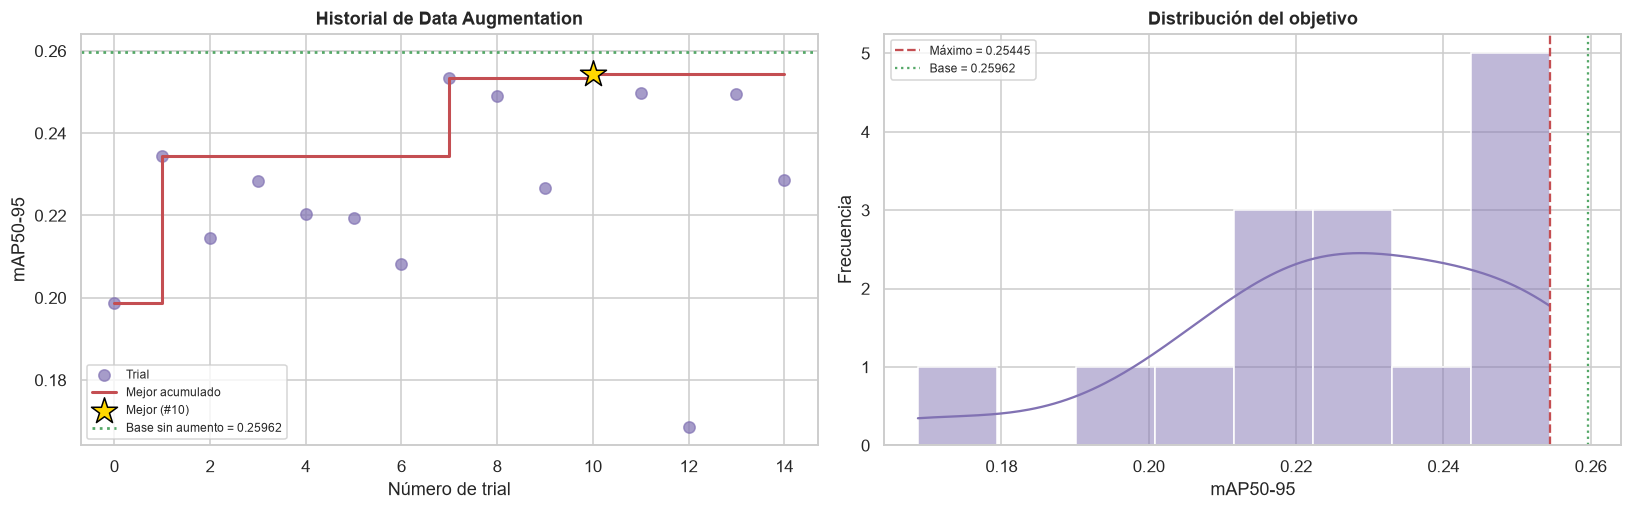

In [53]:
df_hist_aug = df_aug.sort_values("number").copy()
df_hist_aug["mejor_acumulado"] = df_hist_aug["map50_95"].cummax()

mejor_aug = df_aug.loc[df_aug["map50_95"].idxmax()]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

axes[0].scatter(df_hist_aug["number"], df_hist_aug["map50_95"],
                s=55, alpha=0.7, color="#8172B3", label="Trial")
axes[0].step(df_hist_aug["number"], df_hist_aug["mejor_acumulado"],
             where="post", color="#C44E52", linewidth=2, label="Mejor acumulado")
axes[0].scatter(mejor_aug["number"], mejor_aug["map50_95"], marker="*",
                s=320, color="gold", edgecolor="black", zorder=5,
                label=f"Mejor (#{int(mejor_aug['number'])})")
axes[0].axhline(map_base_aug, color="#55A868", linestyle=":",
                linewidth=1.8, label=f"Base sin aumento = {map_base_aug:.5f}")
axes[0].set_xlabel("Número de trial")
axes[0].set_ylabel("mAP50-95")
axes[0].set_title("Historial de Data Augmentation")
axes[0].legend(fontsize=8)

sns.histplot(df_aug["map50_95"], bins=8, kde=True, color="#8172B3", ax=axes[1])
axes[1].axvline(mejor_aug["map50_95"], color="#C44E52", linestyle="--",
                label=f"Máximo = {mejor_aug['map50_95']:.5f}")
axes[1].axvline(map_base_aug, color="#55A868", linestyle=":",
                label=f"Base = {map_base_aug:.5f}")
axes[1].set_xlabel("mAP50-95")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title("Distribución del objetivo")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

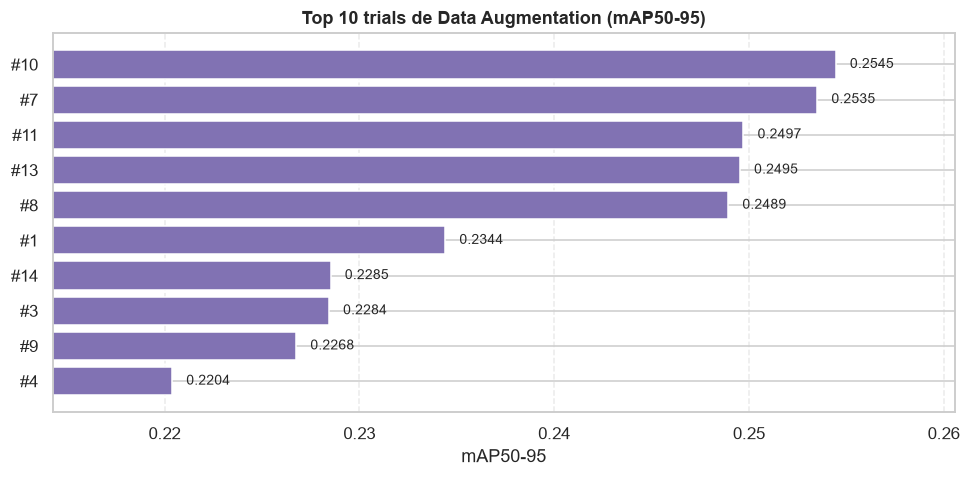

,ranking,number,map50_95,tiempo_minutos,params_degrees,params_erasing,params_fliplr,params_flipud,params_hsv_s,params_hsv_v,params_perspective,params_scale,params_translate
0,1,10,0.2544,13.8927,8.5266,0.9863,0.4549,0.1278,0.9844,0.0469,0.0010,0.2461,0.2726
1,2,7,0.2535,14.3990,14.9751,0.8853,0.5725,0.0957,0.6747,0.8423,0.0002,0.2437,0.7637
2,3,11,0.2497,12.4332,2.3035,0.9877,0.4879,0.0153,0.9988,0.1049,0.0010,0.2272,0.2058
3,4,13,0.2495,14.2722,27.8613,0.9441,0.3395,0.0123,0.0234,0.9827,0.0007,0.0359,0.7388
4,5,8,0.2489,13.5250,2.9033,0.3188,0.1531,0.6955,0.6272,0.7234,0.0002,0.5568,0.5944
5,6,1,0.2344,14.6519,131.2289,0.1755,0.7380,0.1825,0.3921,0.3432,0.0004,0.0597,0.4386
6,7,14,0.2285,14.6718,52.2591,0.7752,0.6020,0.1650,0.8386,0.7554,0.0008,0.2310,0.0049
7,8,3,0.2284,14.6152,113.5757,0.3123,0.4937,0.4258,0.2283,0.2937,0.0004,0.4337,0.0921
8,9,9,0.2268,14.0645,70.0111,0.3982,0.0436,0.3048,0.6920,0.5544,0.0004,0.8417,0.9251
9,10,4,0.2204,14.5041,169.9488,0.8663,0.3173,0.4148,0.4264,0.8934,0.0001,0.6240,0.5018


In [30]:
tabla_aug = df_aug[["number", "map50_95", "tiempo_minutos"] + params_aug].copy()
tabla_aug = tabla_aug.sort_values("map50_95", ascending=False).reset_index(drop=True)
tabla_aug.insert(0, "ranking", tabla_aug.index + 1)

barras_horizontales(
    tabla_aug.head(10).set_index("number")["map50_95"].rename(lambda x: f"#{int(x)}"),
    "Top 10 trials de Data Augmentation (mAP50-95)",
    "mAP50-95",
    color="#8172B3",
    figsize=(9, 4.5),
)

tabla_aug.head(10).round(4)



## 5. Comparación final y modelo ganador

In [54]:
mejor_baseline = df_baseline.sort_values("map50_95", ascending=False).iloc[0]
referencia_26 = df_baseline.loc[df_baseline["modelo_yolo"] == "yolo26m"].iloc[0]

def fila_final(etapa, modelo, epocas, batch, lr, optimizer, data_aug,
               map50, map50_95, precision, recall, tiempo_minutos, fuente):
    return {
        "etapa": etapa,
        "modelo": modelo,
        "epocas": int(epocas),
        "batch": int(batch),
        "lr": float(lr),
        "optimizer": optimizer,
        "data_aug": data_aug,
        "map50": map50,
        "map50_95": float(map50_95),
        "precision": precision,
        "recall": recall,
        "tiempo_minutos": float(tiempo_minutos),
        "fuente": fuente,
    }


finalistas = pd.DataFrame([
    fila_final("1. Baseline · mejor global", mejor_baseline["modelo_yolo"],
               mejor_baseline["epocas_fin"], mejor_baseline["batch"],
               mejor_baseline["learning_rate"], mejor_baseline["optimizer"], "No",
               mejor_baseline["map50"], mejor_baseline["map50_95"],
               mejor_baseline["precision"], mejor_baseline["recall"],
               mejor_baseline["tiempo_minutos"],
               f"modelos_baselines_11.csv ({mejor_baseline['modelo_yolo']})"),
    fila_final("1. Baseline · yolo26m (referencia)", referencia_26["modelo_yolo"],
               referencia_26["epocas_fin"], referencia_26["batch"],
               referencia_26["learning_rate"], referencia_26["optimizer"], "No",
               referencia_26["map50"], referencia_26["map50_95"],
               referencia_26["precision"], referencia_26["recall"],
               referencia_26["tiempo_minutos"],
               "modelos_baselines_11.csv (yolo26m)"),
    fila_final("2. Grid Search · mejor", "yolo26m",
               mejor_gs["epocas_inicial"], mejor_gs["batch"],
               mejor_gs["learning_rate"], mejor_gs["optimizer"], "No",
               mejor_gs["map50"], mejor_gs["map50_95"],
               mejor_gs["precision"], mejor_gs["recall"],
               mejor_gs["tiempo_minutos"],
               f"yolo26_ft_gs_11.csv (numero={int(mejor_gs['numero'])})"),
    fila_final("3. Optuna · mejor", "yolo26m",
               mejor_opt["epochs"], mejor_opt["batch"], mejor_opt["lr"],
               mejor_opt["optimizer"], "No",
               np.nan, mejor_opt["map50_95"], np.nan, np.nan,
               mejor_opt["tiempo_minutos"],
               f"yolo26_ft_opt_11.csv (number={int(mejor_opt['number'])})"),
    fila_final("4. Data Augmentation · mejor", "yolo26m",
               AUG_EPOCHS, AUG_BATCH, AUG_LR, AUG_OPTIMIZER, "Sí",
               np.nan, mejor_aug["map50_95"], np.nan, np.nan,
               mejor_aug["tiempo_minutos"],
               f"yolo26_data_augmentation_11.csv (number={int(mejor_aug['number'])})"),
])

finalistas["metricas_completas"] = finalistas[["map50", "precision", "recall"]].notna().all(axis=1)
referencia = float(referencia_26["map50_95"])
finalistas["delta_vs_yolo26m"] = finalistas["map50_95"] - referencia
finalistas["delta_rel_%"] = 100 * finalistas["delta_vs_yolo26m"] / referencia
finalistas["map50_95_por_min"] = finalistas["map50_95"] / finalistas["tiempo_minutos"]
finalistas = finalistas.sort_values("map50_95", ascending=False).reset_index(drop=True)
finalistas.insert(0, "ranking", finalistas.index + 1)

finalistas.round(4)

,ranking,etapa,modelo,epocas,batch,lr,optimizer,data_aug,map50,map50_95,precision,recall,tiempo_minutos,fuente,metricas_completas,delta_vs_yolo26m,delta_rel_%,map50_95_por_min
0,1,2. Grid Search · mejor,yolo26m,100,6,0.0100,SGD,No,0.6686,0.2617,0.6740,0.6550,5.7630,yolo26_ft_gs_11.csv (numero=27),True,0.0163,6.6411,0.0454
1,2,3. Optuna · mejor,yolo26m,291,11,0.0022,SGD,No,NaN,0.2596,NaN,NaN,9.5808,yolo26_ft_opt_11.csv (number=41),False,0.0142,5.7774,0.0271
2,3,4. Data Augmentation · mejor,yolo26m,291,11,0.0022,SGD,Sí,NaN,0.2544,NaN,NaN,13.8927,yolo26_data_augmentation_11.csv (number=10),False,0.0090,3.6710,0.0183
3,4,1. Baseline · mejor global,yolo12m,100,16,0.0100,auto,No,0.6542,0.2495,0.6571,0.6657,4.9168,modelos_baselines_11.csv (yolo12m),True,0.0040,1.6379,0.0507
4,5,1. Baseline · yolo26m (referencia),yolo26m,100,16,0.0100,auto,No,0.6583,0.2454,0.6854,0.6430,4.8573,modelos_baselines_11.csv (yolo26m),True,0.0000,0.0000,0.0505


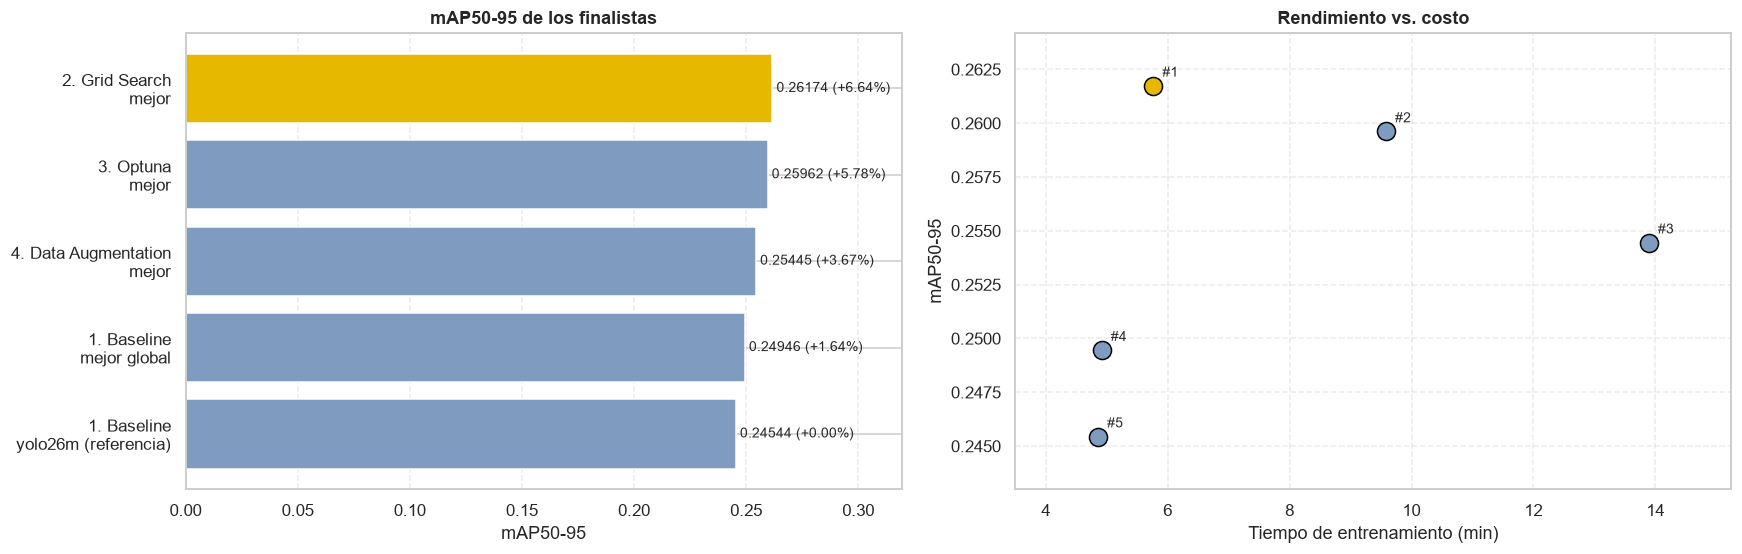

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

datos = finalistas.iloc[::-1]
etiquetas = datos["etapa"].str.replace(" · ", "\n", regex=False)
colores = ["#E6B800" if etapa.startswith("2.") else "#7F9CC0" for etapa in datos["etapa"]]

axes[0].barh(etiquetas, datos["map50_95"], color=colores)
for y, (valor, delta) in enumerate(zip(datos["map50_95"], datos["delta_rel_%"])):
    axes[0].text(valor, y, f" {valor:.5f} ({delta:+.2f}%)", va="center", fontsize=9)
axes[0].set_xlim(0, datos["map50_95"].max() * 1.22)
axes[0].set_xlabel("mAP50-95")
axes[0].set_title("mAP50-95 de los finalistas")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

for _, fila in finalistas.iterrows():
    axes[1].scatter(fila["tiempo_minutos"], fila["map50_95"], s=140,
                    color="#E6B800" if fila["ranking"] == 1 else "#7F9CC0",
                    edgecolor="black", zorder=3)
    axes[1].annotate(f"#{int(fila['ranking'])}", (fila["tiempo_minutos"], fila["map50_95"]),
                     xytext=(6, 6), textcoords="offset points", fontsize=9)
axes[1].set_xlabel("Tiempo de entrenamiento (min)")
axes[1].set_ylabel("mAP50-95")
axes[1].set_title("Rendimiento vs. costo")
axes[1].margins(x=0.15, y=0.15)
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [57]:
# ---------------------------------------------------------------------------
# QUEDARSE CON EL MODELO GANADOR
# Se conserva únicamente la fila ganadora y se descartan los demás finalistas.
# ---------------------------------------------------------------------------
columnas_ganador = ["etapa", "modelo", "epocas", "batch", "lr", "optimizer",
                    "data_aug", "map50", "map50_95", "precision", "recall",
                    "tiempo_minutos", "delta_rel_%", "score_final"]

df_modelo_ganador = (
    finalistas.loc[finalistas["ranking"] == 1, columnas_ganador]
    .reset_index(drop=True)
)

descartados = finalistas.loc[finalistas["ranking"] != 1, "etapa"].tolist()

print("MODELO CONSERVADO:")
print(df_modelo_ganador.round(4).to_string(index=False))
print()
print("Finalistas descartados:")
for etapa in descartados:
    print(f"  - {etapa}")

df_modelo_ganador.round(4)

MODELO CONSERVADO:
                 etapa  modelo  epocas  batch     lr optimizer data_aug  map50  map50_95  precision  recall  tiempo_minutos  delta_rel_%  score_final
2. Grid Search · mejor yolo26m     100      6 0.0100       SGD       No 0.6686    0.2617     0.6740  0.6550          5.7630       6.6411       0.9754

Finalistas descartados:
  - 3. Optuna · mejor
  - 4. Data Augmentation · mejor
  - 1. Baseline · mejor global
  - 1. Baseline · yolo26m (referencia)


,etapa,modelo,epocas,batch,lr,optimizer,data_aug,map50,map50_95,precision,recall,tiempo_minutos,delta_rel_%,score_final
0,2. Grid Search · mejor,yolo26m,100,6,0.0100,SGD,No,0.6686,0.2617,0.6740,0.6550,5.7630,6.6411,0.9754


## 6. Conclusiones

1. **Baseline.** `yolo12m` obtiene el mejor mAP50-95 (0.24946), seguido muy de cerca por `yolo26m` (0.24544). La diferencia (≈1.6 % relativo) no es concluyente con 38 imágenes de validación; `yolo26m` lidera mAP50 (0.65828) y precisión (0.68539), por lo que se mantiene como base del fine-tuning.
2. **Grid Search.** La mejor configuración es **100 épocas, batch 6, lr 0.01 y SGD**, con **mAP50-95 = 0.26174**, **mAP50 = 0.66858**, precisión 0.67400 y recall 0.65498, en 5.76 min. Mejora al baseline `yolo26m` en **+6.6 %** y al mejor baseline en **+4.9 %**. Además, es el finalista más eficiente.
3. **Optuna.** El mejor trial (**batch 11, 291 épocas, lr 0.00215, SGD**) alcanza **0.25962** en 9.58 min. No supera al Grid Search (−0.8 % relativo) y tarda 1.7× más. El learning rate concentra la importancia (ρ ≈ -0.92) y el mejor resultado apareció a mitad de la búsqueda, dejando ~5 h de trials sin mejora.
4. **Data Augmentation.** El mejor trial alcanza **0.25445**, un **-2.0 %** frente a su configuración base (0.25962) y **-2.8 %** frente al Grid Search. `flipud`, `scale` y `degrees` muestran correlación negativa: el rango explorado fue demasiado agresivo. La etapa se descarta.
5. **Modelo ganador.** **`yolo26m` con 100 épocas, batch 6, lr 0.01 y optimizador SGD** (Grid Search, corrida #27), con **mAP50-95 = 0.26174** y score final ≈ 0.98. Es el mejor rendimiento absoluto y el mejor equilibrio rendimiento/costo.
